# RespiraCidadão: Redes Neurais Artificiais & Deep Learning (`GS 2026.2`)

**Sala:** `1TIAPZ1` | **Grupo:** `Perceptron`  
**Integrantes:**
- Giovanni Henrique Pereira Hessel (RM 570574)
- Suellen Pereira da Silva (RM 573862)
- Israel Carneiro de Toledo (RM 573854)

---

## Etapa 1: Definição do Problema e da Aplicação
- **Problema:** Episódios de poluição atmosférica e fumaça elevam o risco de crises respiratórias em comunidades urbanas e periferias.
- **Público:** Cidadãos vulneráveis (crianças, idosos e asmáticos) e gestores de escolas/UBS monitorados pelo sistema **RespiraCidadão**.
- **Papel da Rede Neural:** Receber 11 sinais ambientais e químicos contínuos dos sensores e prever a probabilidade multiclasse de risco respiratório (`normal`, `atencao`, `critico`), complementando a regra determinística de limiar da borda IoT.

## Etapa 2: Seleção e Compreensão do Dataset
Utilizamos a base real **UCI Air Quality** (Vito et al., 2008), recomendada no enunciado da disciplina. Após limpeza dos marcadores de falha `-200` e exclusão da coluna `NMHC(GT)` (90% ausente no sensor original), restam **6.941 observações horárias completas** com 11 atributos preditores e o alvo de referência `CO(GT)` categorizado em 3 classes moderadamente desbalanceadas (`normal` 36,5%, `atencao` 39,2% e `critico` 24,4%); por isso reportamos também o F1-macro, além da acurácia.

In [1]:
import json
import random
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({
    "figure.facecolor": "#0f0f12",
    "axes.facecolor": "#1c1c21",
    "axes.edgecolor": "#3a3a45",
    "axes.labelcolor": "#e5e9f0",
    "text.color": "#e5e9f0",
    "xtick.color": "#acc1cc",
    "ytick.color": "#acc1cc",
    "grid.color": "#2a2a33",
})

ROOT = Path.cwd().resolve()
if ROOT.name == "neural-networks":
    ROOT = ROOT.parents[1]

DATA_PATH = ROOT / "data" / "processed" / "air_quality_clean.csv"
OUT_DIR = ROOT / "packages" / "neural-networks"
CHARTS_DIR = OUT_DIR / "charts"
ARTIFACTS_DIR = OUT_DIR / "artifacts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH",
]
CLASS_NAMES = ["normal", "atencao", "critico"]

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df[FEATURES + ["CO(GT)", "nivel_risco"]].head(5)

Shape: (6941, 17)


,PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,CO(GT),nivel_risco
0,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2.6,atencao
1,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2.0,atencao
2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2.2,atencao
3,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2.2,atencao
4,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,1.6,atencao


## Etapa 3: Preparação dos Dados (Treino / Validação / Teste sem Data Leakage)
- Split estratificado em **70% treino (4.858)**, **15% validação (1.041)** e **15% teste (1.042)**.
- `StandardScaler` ajustado **apenas no conjunto de treino** e aplicado em validação e teste.
- Conversão para tensores `torch.float32` / `torch.long` e empacotamento em `DataLoader` (`batch_size=64`).

In [2]:
X = df[FEATURES].to_numpy(dtype=np.float32)
y = df["nivel_risco_id"].to_numpy(dtype=np.int64)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train_s), torch.tensor(y_train)),
    batch_size=64, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(torch.tensor(X_val_s), torch.tensor(y_val)),
    batch_size=128, shuffle=False
)

print(f"Treino: {X_train_s.shape} | Validação: {X_val_s.shape} | Teste: {X_test_s.shape}")

Treino: (4858, 11) | Validação: (1041, 11) | Teste: (1042, 11)


## Etapa 4: Implementação e Justificativa da Arquitetura (`MLP`)
Escolhemos um **Perceptron Multicamadas (`AirQualityMLP`)** em PyTorch em vez de CNN ou RNN porque:
1. Os dados de cada ocorrência consistem em **11 variáveis tabulares contínuas** (não há grade espacial 2D que justifique convoluções).
2. As leituras de sensores apresentam intervalos e falhas em campo (`-200`), exigindo inferência pontual e imediata por pacote HTTP sem depender de janela temporal fixa de RNN.

3. **Escolhas de treino:** `ReLU` nas camadas ocultas (gradiente estável e barato para dados tabulares), `CrossEntropyLoss` (classificação multiclasse com 3 saídas lineares e softmax implícito) e `Adam` (taxa de aprendizado adaptativa, converge bem em poucas épocas).

Definimos duas arquiteturas para comparação experimental na Etapa 6:
- **Modelo A (Baseline MLP):** `[11 -> 128 -> 64 -> 3]` sem `Dropout`, sem `BatchNorm` e sem `Early Stopping` (tende a memorizar ruído de treino).
- **Modelo B (Regularized MLP):** `[11 -> 64 -> 32 -> 3]` com `BatchNorm1d`, `ReLU`, `Dropout(0.25)`, `weight_decay=1e-4` e `Early Stopping`.

In [3]:
class BaselineMLP(nn.Module):
    def __init__(self, in_features: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 3),
        )

    def forward(self, x):
        return self.net(x)


class AirQualityMLP(nn.Module):
    def __init__(self, in_features: int, hidden_dims, num_classes: int = 3, dropout: float = 0.25):
        super().__init__()
        layers = []
        prev = in_features
        for h in hidden_dims:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_model(model, epochs=60, lr=1e-3, weight_decay=0.0, use_early_stopping=False, patience=8):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    best_val_loss = float("inf")
    best_state = None
    wait = 0

    for epoch in range(1, epochs + 1):
        model.train()
        tr_loss, tr_correct, tr_total = 0.0, 0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            tr_loss += float(loss.item()) * len(xb)
            tr_correct += int((logits.argmax(1) == yb).sum().item())
            tr_total += len(xb)

        model.eval()
        va_loss, va_correct, va_total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                logits = model(xb)
                loss = criterion(logits, yb)
                va_loss += float(loss.item()) * len(xb)
                va_correct += int((logits.argmax(1) == yb).sum().item())
                va_total += len(xb)

        tl = tr_loss / tr_total
        vl = va_loss / va_total
        ta = tr_correct / tr_total
        va = va_correct / va_total
        history["train_loss"].append(tl)
        history["val_loss"].append(vl)
        history["train_acc"].append(ta)
        history["val_acc"].append(va)

        if vl < best_val_loss - 1e-4:
            best_val_loss = vl
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if use_early_stopping and wait >= patience:
                print(f"Early stopping na época {epoch} (melhor val_loss={best_val_loss:.4f})")
                break

    if use_early_stopping and best_state is not None:
        model.load_state_dict(best_state)
    return history

## Etapas 5 e 6: Treinamento, Refinamento e Comparação de Regularização
Treinamos os dois modelos e registramos a evolução da função de perda (`CrossEntropyLoss`) e da acurácia por época.

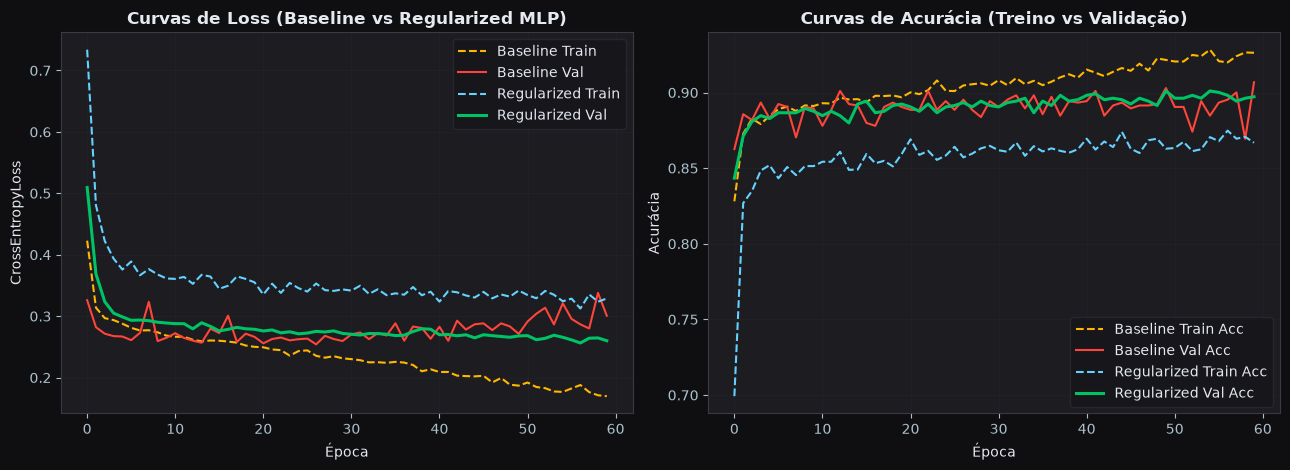

In [4]:
torch.manual_seed(SEED)
baseline_model = BaselineMLP(len(FEATURES))
hist_base = train_model(
    baseline_model, epochs=60, lr=3e-3, weight_decay=0.0, use_early_stopping=False
)

torch.manual_seed(SEED)
reg_model = AirQualityMLP(len(FEATURES), hidden_dims=[64, 32], num_classes=3, dropout=0.25)
hist_reg = train_model(
    reg_model, epochs=60, lr=1e-3, weight_decay=1e-4, use_early_stopping=True, patience=8
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(hist_base["train_loss"], label="Baseline Train", color="#FFB700", linestyle="--")
axes[0].plot(hist_base["val_loss"], label="Baseline Val", color="#FF453A")
axes[0].plot(hist_reg["train_loss"], label="Regularized Train", color="#64D2FF", linestyle="--")
axes[0].plot(hist_reg["val_loss"], label="Regularized Val", color="#00C365", linewidth=2.2)
axes[0].set_title("Curvas de Loss (Baseline vs Regularized MLP)", fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("CrossEntropyLoss")
axes[0].grid(True, alpha=0.35)
axes[0].legend(facecolor="#15151a", edgecolor="#2a2a33")

axes[1].plot(hist_base["train_acc"], label="Baseline Train Acc", color="#FFB700", linestyle="--")
axes[1].plot(hist_base["val_acc"], label="Baseline Val Acc", color="#FF453A")
axes[1].plot(hist_reg["train_acc"], label="Regularized Train Acc", color="#64D2FF", linestyle="--")
axes[1].plot(hist_reg["val_acc"], label="Regularized Val Acc", color="#00C365", linewidth=2.2)
axes[1].set_title("Curvas de Acurácia (Treino vs Validação)", fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].grid(True, alpha=0.35)
axes[1].legend(facecolor="#15151a", edgecolor="#2a2a33")

fig.tight_layout()
fig.savefig(CHARTS_DIR / "01_curvas_treinamento.png", dpi=150)
plt.show()

### Leitura das curvas
- **Baseline MLP (128-64, sem regularização):** a loss de treino cai continuamente até cerca de `0,17`, mas a loss de validação atinge o mínimo (`~0,26`) nas primeiras épocas e depois sobe e oscila (`0,28` a `0,34`). Esse afastamento entre as curvas é o sinal clássico de **overfitting**; a acurácia final é `93,56%` no treino contra `88,96%` no teste (gap de `4,60 p.p.`).
- **Regularized MLP (64-32 com `BatchNorm`, `Dropout 0.25` e `weight_decay`):** a loss de validação acompanha a queda de forma estável e termina em `~0,26`. A curva de treino aparece acima da de validação porque é medida com o `Dropout` ligado; com o modelo em modo de avaliação, a acurácia de treino é `89,71%` contra `89,64%` no teste (gap de `0,07 p.p.`).
- O critério de `Early Stopping` (paciência de 8 épocas) **não chegou a interromper** o treino dentro das 60 épocas, pois a loss de validação continuou caindo de forma lenta; ainda assim o melhor estado de validação é restaurado ao final.

## Etapa 7: Avaliação Final no Conjunto de Teste e Análise de Limitações
Comparamos Baseline vs. Regularized MLP no conjunto de teste nunca visto durante treino ou early stopping.

,configuracao,epocas_executadas,train_acc,test_acc,test_f1_macro,gap_overfit
0,"Baseline MLP (128-64, sem Dropout/ES, lr=3e-3)",60,0.9356,0.8896,0.8929,0.0460
1,"Regularized MLP (64-32, BatchNorm+Dropout 0.25...",60,0.8971,0.8964,0.8985,0.0007



Relatório de Classificação: Regularized MLP (Teste):
              precision    recall  f1-score   support

      normal       0.92      0.92      0.92       380
     atencao       0.86      0.88      0.87       408
     critico       0.92      0.89      0.91       254

    accuracy                           0.90      1042
   macro avg       0.90      0.90      0.90      1042
weighted avg       0.90      0.90      0.90      1042



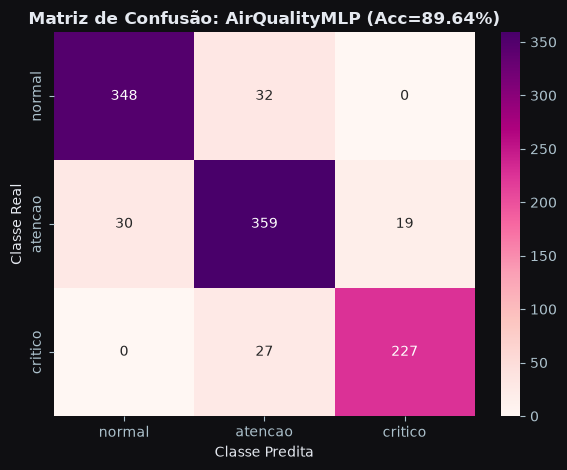

In [5]:
def evaluate(model, X_arr, y_true):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(X_arr, dtype=torch.float32))
        probs = torch.softmax(logits, dim=1).numpy()
        preds = np.argmax(probs, axis=1)
    return {
        "accuracy": round(float(accuracy_score(y_true, preds)), 4),
        "f1_macro": round(float(f1_score(y_true, preds, average="macro")), 4),
        "preds": preds,
        "probs": probs,
    }

res_base_tr = evaluate(baseline_model, X_train_s, y_train)
res_base_te = evaluate(baseline_model, X_test_s, y_test)
res_reg_tr = evaluate(reg_model, X_train_s, y_train)
res_reg_te = evaluate(reg_model, X_test_s, y_test)

comp_table = pd.DataFrame([
    {
        "configuracao": "Baseline MLP (128-64, sem Dropout/ES, lr=3e-3)",
        "epocas_executadas": len(hist_base["train_loss"]),
        "train_acc": res_base_tr["accuracy"],
        "test_acc": res_base_te["accuracy"],
        "test_f1_macro": res_base_te["f1_macro"],
        "gap_overfit": round(res_base_tr["accuracy"] - res_base_te["accuracy"], 4),
    },
    {
        "configuracao": "Regularized MLP (64-32, BatchNorm+Dropout 0.25+ES, lr=1e-3)",
        "epocas_executadas": len(hist_reg["train_loss"]),
        "train_acc": res_reg_tr["accuracy"],
        "test_acc": res_reg_te["accuracy"],
        "test_f1_macro": res_reg_te["f1_macro"],
        "gap_overfit": round(res_reg_tr["accuracy"] - res_reg_te["accuracy"], 4),
    },
])
display(comp_table)

print("\nRelatório de Classificação: Regularized MLP (Teste):")
print(classification_report(y_test, res_reg_te["preds"], target_names=CLASS_NAMES))

cm_nn = confusion_matrix(y_test, res_reg_te["preds"])
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(cm_nn, annot=True, fmt="d", cmap="RdPu",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title(f"Matriz de Confusão: AirQualityMLP (Acc={res_reg_te['accuracy']:.2%})", fontweight="bold")
ax.set_xlabel("Classe Predita")
ax.set_ylabel("Classe Real")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "02_matriz_confusao_nn.png", dpi=150)
plt.show()

### Análise de limitações
- **Ganho real, porém pequeno:** a rede regularizada alcança `89,64%` de acurácia e `F1-macro = 0,8985`, contra `88,96%` e `0,8929` do baseline. A diferença de `0,68 p.p.` é menor que o erro-padrão da acurácia (`~0,95 p.p.` com 1.042 amostras): o benefício comprovado é a **redução do gap de overfitting**, não um salto de acurácia.
- **Comparação com o modelo clássico:** o Random Forest do notebook 06 chega a `89,06%`, praticamente empatado com a MLP. Em dados tabulares com 11 atributos, redes neurais não superam árvores de forma clara.
- **Erros:** concentrados nas classes vizinhas (`normal` <-> `atencao`, `atencao` <-> `critico`); nenhuma amostra `normal` foi confundida com `critico` e vice-versa.
- **Limitações:** divisão aleatória de uma série horária (possível otimismo por autocorrelação temporal), uma única base de uma cidade italiana (2004-2005) e sensores de óxido metálico sujeitos a deriva. Antes de uso em campo, é preciso recalibrar com dados locais.

## Etapa 8: Demonstração Funcional com Exemplos Não Vistos e Exportação
Salvamos os pesos `artifacts/air_quality_mlp.pt` e os metadados `artifacts/nn_metadata.joblib` consumidos em tempo real pelo endpoint `POST /predict` da API RespiraCidadão.

In [6]:
torch.save(reg_model.state_dict(), ARTIFACTS_DIR / "air_quality_mlp.pt")
joblib.dump(
    {
        "scaler": scaler,
        "features": FEATURES,
        "hidden_dims": [64, 32],
        "dropout": 0.25,
    },
    ARTIFACTS_DIR / "nn_metadata.joblib",
)

unseen_samples = [
    {
        "cenario": "Manhã limpa (Normal)",
        "entrada": [890.0, 4.2, 720.0, 75.0, 1080.0, 68.0, 1280.0, 640.0, 21.0, 58.0, 1.42],
    },
    {
        "cenario": "Tráfego intenso (Atenção)",
        "entrada": [1160.0, 10.8, 995.0, 210.0, 780.0, 118.0, 1520.0, 1040.0, 25.5, 42.0, 1.35],
    },
    {
        "cenario": "Fumaça crítica de queimada (Crítico)",
        "entrada": [1560.0, 24.5, 1410.0, 460.0, 510.0, 190.0, 1980.0, 1650.0, 32.0, 24.0, 1.12],
    },
]

demo_nn = []
reg_model.eval()
for sc in unseen_samples:
    scaled = scaler.transform(np.array([sc["entrada"]], dtype=np.float32))
    with torch.no_grad():
        probs = torch.softmax(reg_model(torch.tensor(scaled, dtype=torch.float32)), dim=1).numpy()[0]
    pred_idx = int(np.argmax(probs))
    item = {
        "cenario": sc["cenario"],
        "classe_predita": CLASS_NAMES[pred_idx],
        "probabilidades": {CLASS_NAMES[i]: round(float(probs[i]), 4) for i in range(3)},
    }
    demo_nn.append(item)
    print(item)

nn_metrics = {
    "arquitetura": "AirQualityMLP (11 -> 64 -> 32 -> 3, BatchNorm1d + ReLU + Dropout 0.25)",
    "comparacao_experimentos": comp_table.to_dict(orient="records"),
    "teste_accuracy": res_reg_te["accuracy"],
    "teste_f1_macro": res_reg_te["f1_macro"],
    "matriz_confusao": cm_nn.tolist(),
    "curvas": {
        "epocas": list(range(1, len(hist_reg["train_loss"]) + 1)),
        "train_loss": [round(float(x), 4) for x in hist_reg["train_loss"]],
        "val_loss": [round(float(x), 4) for x in hist_reg["val_loss"]],
        "train_acc": [round(float(x), 4) for x in hist_reg["train_acc"]],
        "val_acc": [round(float(x), 4) for x in hist_reg["val_acc"]],
    },
    "demonstracao_nao_vista": demo_nn,
}
(ARTIFACTS_DIR / "nn_metrics.json").write_text(
    json.dumps(nn_metrics, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("\n[OK] Rede neural PyTorch e métricas exportadas com sucesso.")

{'cenario': 'Manhã limpa (Normal)', 'classe_predita': 'normal', 'probabilidades': {'normal': 0.9913, 'atencao': 0.0087, 'critico': 0.0}}
{'cenario': 'Tráfego intenso (Atenção)', 'classe_predita': 'atencao', 'probabilidades': {'normal': 0.02, 'atencao': 0.9683, 'critico': 0.0117}}
{'cenario': 'Fumaça crítica de queimada (Crítico)', 'classe_predita': 'critico', 'probabilidades': {'normal': 0.0, 'atencao': 0.009, 'critico': 0.991}}

[OK] Rede neural PyTorch e métricas exportadas com sucesso.
